## Step 1: Import and preprocess

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("Housing.csv")   # use your actual file name
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [2]:
print(df.shape)
df.info()
print(df.isnull().sum())
df.describe()

(545, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom   

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [3]:
# yes/no columns -> 1/0
yes_no_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in yes_no_cols:
    df[col] = df[col].map({'yes': 1, 'no': 0})

# furnishingstatus has 3 categories -> one-hot encoding
df = pd.get_dummies(df, columns=['furnishingstatus'], drop_first=True, dtype=int)
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


In [4]:
print(df.isnull().sum().sum())  

0


## Step 2: Train-test split

In [5]:
X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(436, 13) (109, 13)


## Step 3: Fit the models

In [6]:
X_train_s = X_train[['area']]
X_test_s = X_test[['area']]

simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train)
y_pred_s = simple_model.predict(X_test_s)

In [7]:
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)
y_pred_m = multi_model.predict(X_test)

## Step 4: Evaluate with MAE, MSE, R²Step 4: Evaluate with MAE, MSE, R²

In [8]:
def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"{name}\n  MAE : {mae:,.0f}\n  MSE : {mse:,.0f}\n  RMSE: {rmse:,.0f}\n  R2  : {r2:.3f}\n")

evaluate("Simple (area only)", y_test, y_pred_s)
evaluate("Multiple (all features)", y_test, y_pred_m)

Simple (area only)
  MAE : 1,474,748
  MSE : 3,675,286,604,768
  RMSE: 1,917,104
  R2  : 0.273

Multiple (all features)
  MAE : 970,043
  MSE : 1,754,318,687,331
  RMSE: 1,324,507
  R2  : 0.653



## Step 5: Plot the regression line and interpret coefficients

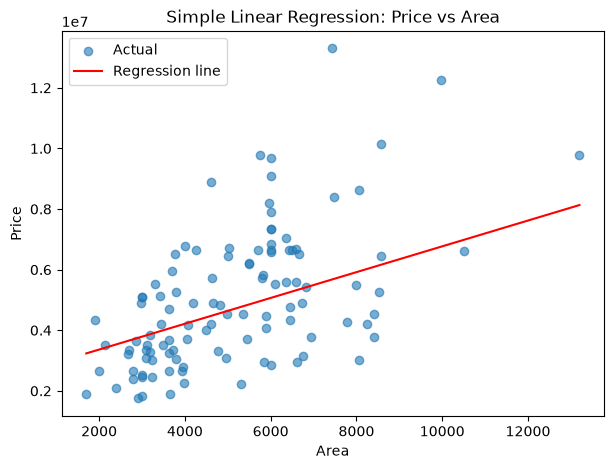

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test_s, y_test, alpha=0.6, label='Actual')
plt.plot(X_test_s.sort_values('area'),
         simple_model.predict(X_test_s.sort_values('area')),
         color='red', label='Regression line')
plt.xlabel('Area')
plt.ylabel('Price')
plt.title('Simple Linear Regression: Price vs Area')
plt.legend()
plt.show()

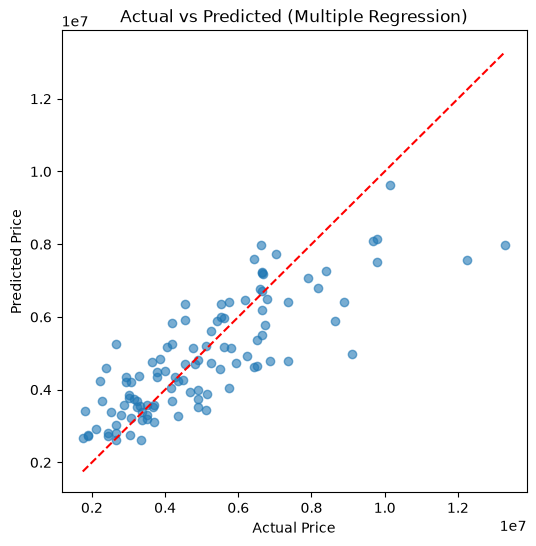

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_m, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted (Multiple Regression)')
plt.show()

In [11]:
print("Simple model: intercept =", simple_model.intercept_, " slope =", simple_model.coef_[0])

coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': multi_model.coef_})
coef_df = coef_df.sort_values('Coefficient', ascending=False)
display(coef_df)

Simple model: intercept = 2512254.2639593435  slope = 425.72984193878284


,Feature,Coefficient
2,bathrooms,1.094445e+06
8,airconditioning,7.914267e+05
7,hotwaterheating,6.846499e+05
10,prefarea,6.298906e+05
3,stories,4.074766e+05
6,basement,3.902512e+05
4,mainroad,3.679199e+05
5,guestroom,2.316100e+05
9,parking,2.248419e+05
1,bedrooms,7.677870e+04


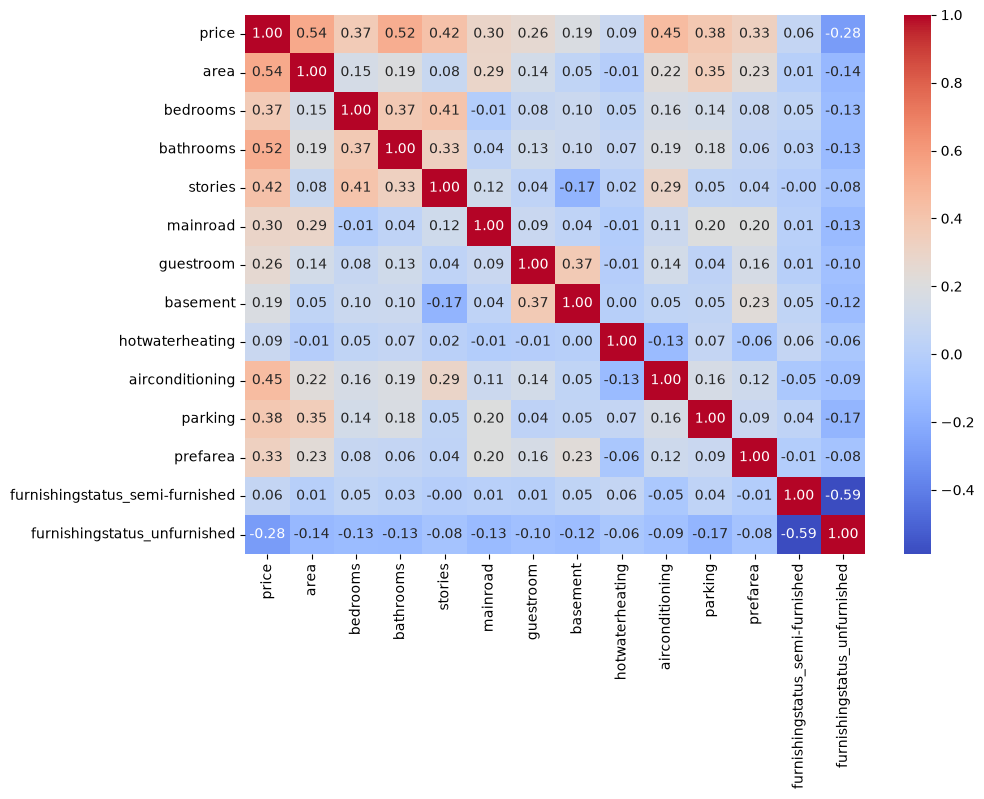

In [12]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

## ## Key Findings
- Multiple regression (all features) reached R² = 0.653, MAE = 970,043 and RMSE = 1,324,507 on the test set.
- Simple regression (area only) reached R² = ____, which is lower, so using more features improves the predictions.
- R² of 0.653 means the model explains about 65% of the variance in house prices.
- Each extra unit of area adds about ____ to the predicted price, holding other features constant.
- The strongest positive features are ____ and ____. [use the top rows of your coefficient table]
- The two furnishing columns are correlated (-0.59) because they come from the same category. This is expected from one-hot encoding. No other pair looks strongly correlated.